# KS1, KS2 and KS3 — neural circuit diagrams

Five source-matched diagrams using the **same PyNCD / tsncd system as
[RHAC](https://github.com/curvedinf/SDGraft/tree/d093ec868246ba86155a7f9d8039c4bec61d9e51/RHAC/docs/diagrams)**. Saved inline figures are included; opening this
notebook does not require PyNCD, Torch, a GPU, or a network connection.
Running the default cells requires IPython and the PNGs in this folder.
Set `RENDER = True` after the setup at the end to redraw from the editable
definitions in [`draw_ks_blocks.py`](../../scripts/draw_ks_blocks.py).

**Reading the diagrams.** One wire is one tensor axis. Dashed separators
divide arrays; branching copies an array; contraction joins and sums an
axis. A shared axis retained in a contraction denotes a pointwise product.
Batch/token axes are omitted. Colored boxes are documented operations,
not executable numerical kernels. Learned coefficients belong to the boxes;
separate wires for parameters are omitted. Chart-indexed boxes have separate
parameters for each chart. The diagrams do not claim training
quality, speed, or quantization equivalence.

**Axes:** `d/e` = input/output feature widths; `i/o` = map input/output
coordinates (`K/N`); `s/r` = chart count/rank (`S/R`); `t` = the singleton
mean coordinate; `b` = six spine terms. The projected wrappers show reshaping
into `[S,R]` as part of their dense projections.

For hover explanations, formulas and source links, open
[the interactive companion](comparison/index.html). It also offers
box-and-arrow views of the same graphs.

In [1]:
from pathlib import Path
from IPython.display import Image, display

RENDER = False  # True: redraw with PyNCD; False: display checked-in PNGs.
root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "scripts/draw_ks_blocks.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Run from this repository or docs/diagrams.")
assets = root / "docs/diagrams"

if RENDER:
    import sys
    sys.path.insert(0, str(root / "scripts"))
    from draw_ks_blocks import build_figures, validate_signatures
    import notebooks.display.notebook_diagrams as diagrams
    from websocket_transfer.headless import HeadlessRenderer
    figures = build_figures()
    validate_signatures(figures)
    settings = diagrams.DiagramSettings(
        dark_mode=diagrams.ColorMode.LIGHT,
        advanced_display=diagrams.AdvancedDisplay.LEGEND,
        sub_blocks=diagrams.SubBlocks.NO_BODIES, width=950)

async def show_figure(name):
    if RENDER:
        message = diagrams.sent_figure(figures[name], settings).message()
        async with HeadlessRenderer(scale=2) as renderer:
            await renderer.render_json(message["data"], message["settings"],
                                       message.get("auxiliary"))
            png = await renderer.capture_rendered(format="png")
    else:
        png = (assets / f"{name}.png").read_bytes()
    display(Image(data=png, width=1100))

## KS1 — the original splanifold map

Source: [`splanifold_map`](../../experiments/common/splanifold.py).
There is no `KS1` class in the common module: this function is the original
geometric map used by the KS1 experiments. It maps `(..., K)` to `(..., N)`.

With extrapolation $epsilon$ and tangent scale $sigma$:
$$u=(1+2\epsilon)r-\epsilon,\quad t=\frac1K\sum_i u_i,\quad
\delta_i=u_i-t,\quad
w_i=\begin{cases}u_i/\sum_j u_j&\sum_j u_j\ne0\\1/K&\text{otherwise.}\end{cases}$$
Write $H(p_0,p_1,v_0,v_1;t)=h_{00}p_0+h_{01}p_1+h_{10}v_0+h_{11}v_1$,
where $h_{00}=2t^3-3t^2+1$, $h_{01}=-2t^3+3t^2$,
$h_{10}=t^3-2t^2+t$ and $h_{11}=t^3-t^2$.
For endpoint $q\in\{0,1\}$, the controls give
$$v_q=\sigma\sum_i w_i(P_{q,i}-a_q),\quad
d_q=\sum_i\delta_i B_{q,i},\quad
e_q=\sigma\sum_i\delta_i(Q_{q,i}-B_{q,i}).$$
The map is $f_1(r)=H(a_0,a_1,v_0,v_1;t)+H(d_0,d_1,e_0,e_1;t)$.
`P` denotes position-tangent control points; `B` endpoint bases; `Q`
basis-tangent control points. The function takes these controls as arguments.

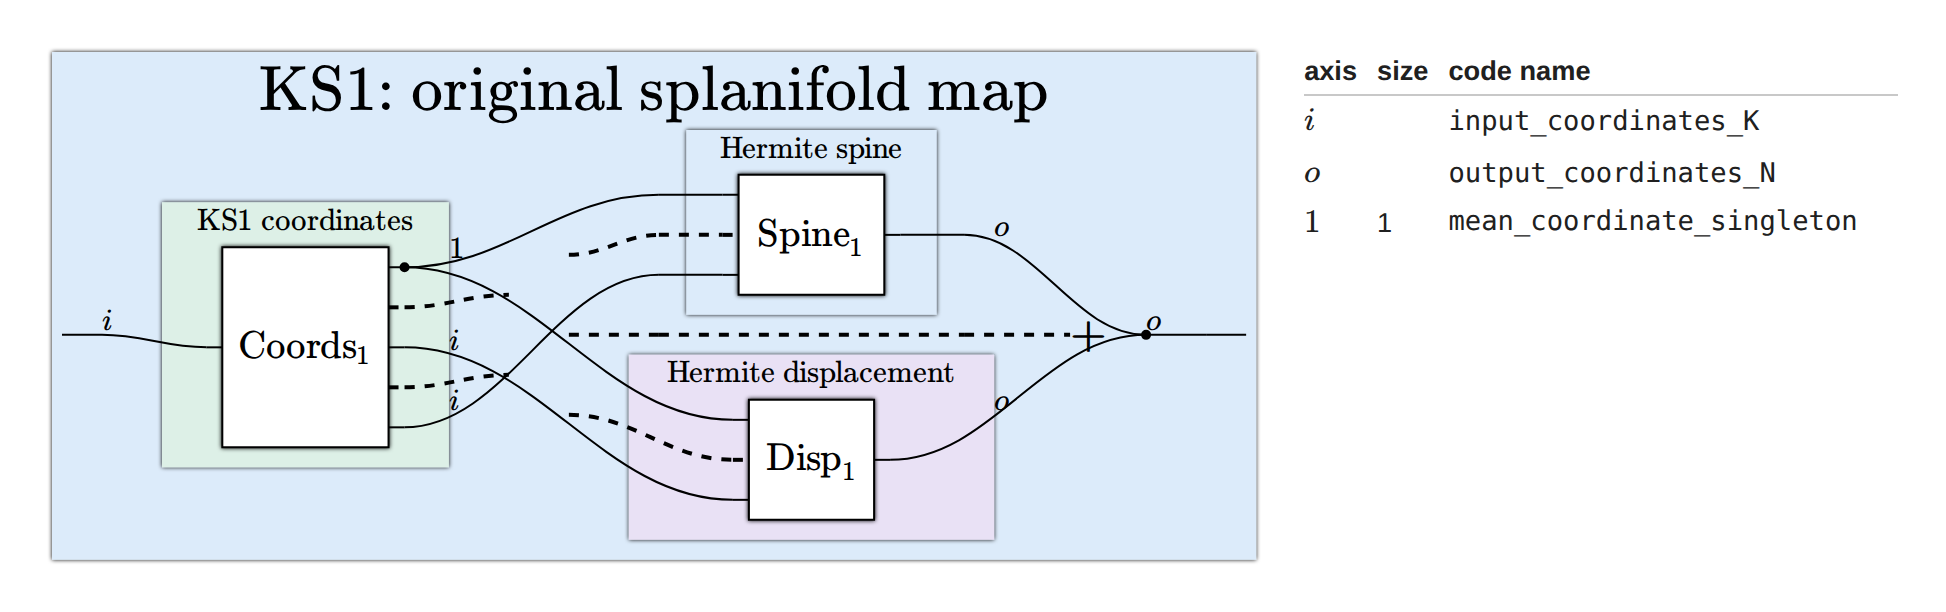

In [2]:
await show_figure("ks1-map")

### KS1 as a projected block

Source: [`KS1Denoiser`](../../experiments/denoising/run.py).
This concrete wrapper fixes input/output width to **169** and rank to **8**;
its chart count is configurable. It learns the chart controls and two
bias-free projections. It bounds the input to the geometric map, then adds
the map's result to the **unsquashed** projected coordinates:
$$c=\operatorname{reshape}(W_{\rm down}x),\quad
y=W_{\rm up}\operatorname{vec}\left[c+f_1\left((1+\tanh c)/2\right)\right].$$
Here $\sigma=1$, $\epsilon=0$. This wrapper is separate from the core map;
it has one chart-space addition and no outer input residual or ReLU.

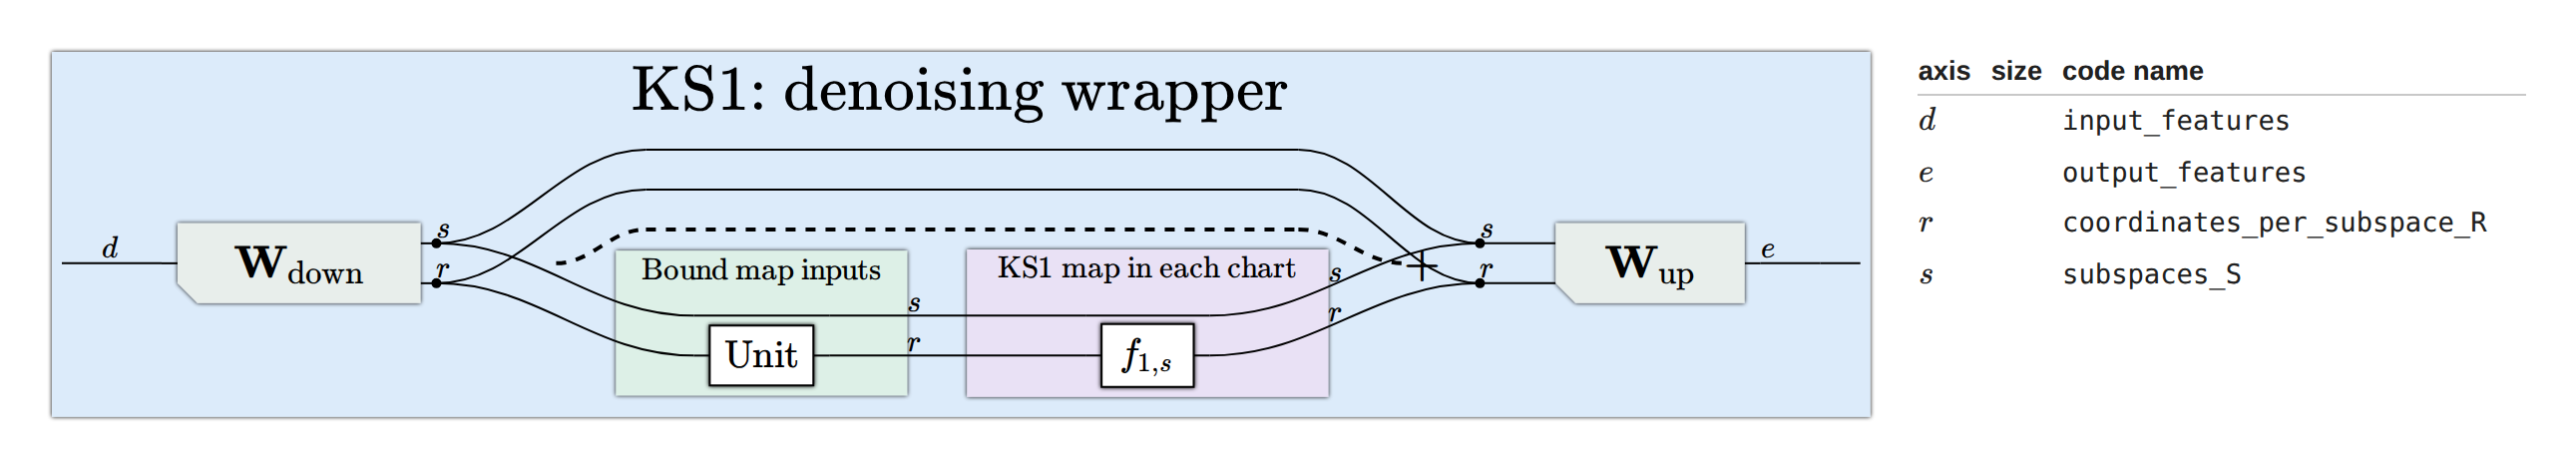

In [3]:
await show_figure("ks1-block")

## KS2 — learned spine and factorized edges

Source: [`KS2`](../../experiments/common/ks2.py). The direct map takes
`(..., K)` to `(..., N)` in one geometric evaluation. Let
$$t=\operatorname{mean}(x),\quad
z(v;a,b)=\tanh[(\operatorname{softplus}(a)+10^{-4})(v+\tfrac12\tanh b)].$$
Its six-term spine basis is
$\Phi(t)=[h_{00}(t),h_{01}(t),h_{10}(t),h_{11}(t),T_2(z(t)),T_3(z(t))]$.
A separate warp gives the coordinate basis $[1,z_i,T_2(z_i),T_3(z_i)]$.
$$L_{io}=\sum_b\Phi_b C^t_{bio},\quad
X_{io}=\sum_{a=0}^3T_a(z_i)C^x_{aio},\quad
f_{2,o}(x)=\sum_b\Phi_b C^{\rm spine}_{bo}+\sum_i\frac{L_{io}X_{io}}{D_{io}}.$$
The original denominator is
$$D_{io}=1+\operatorname{softplus}(\alpha_{io})|x_i-t|
+\operatorname{softplus}(\beta_{io})w_i^2,$$
with $w=x/\sum_i x_i$ except that $|\sum_i x_i|<10^{-6}$ gives $w_i=1/K$.
These are signed weights, not a softmax. The Hermite coordinate is unbounded
in this original implementation; only the Chebyshev coordinate is warped.

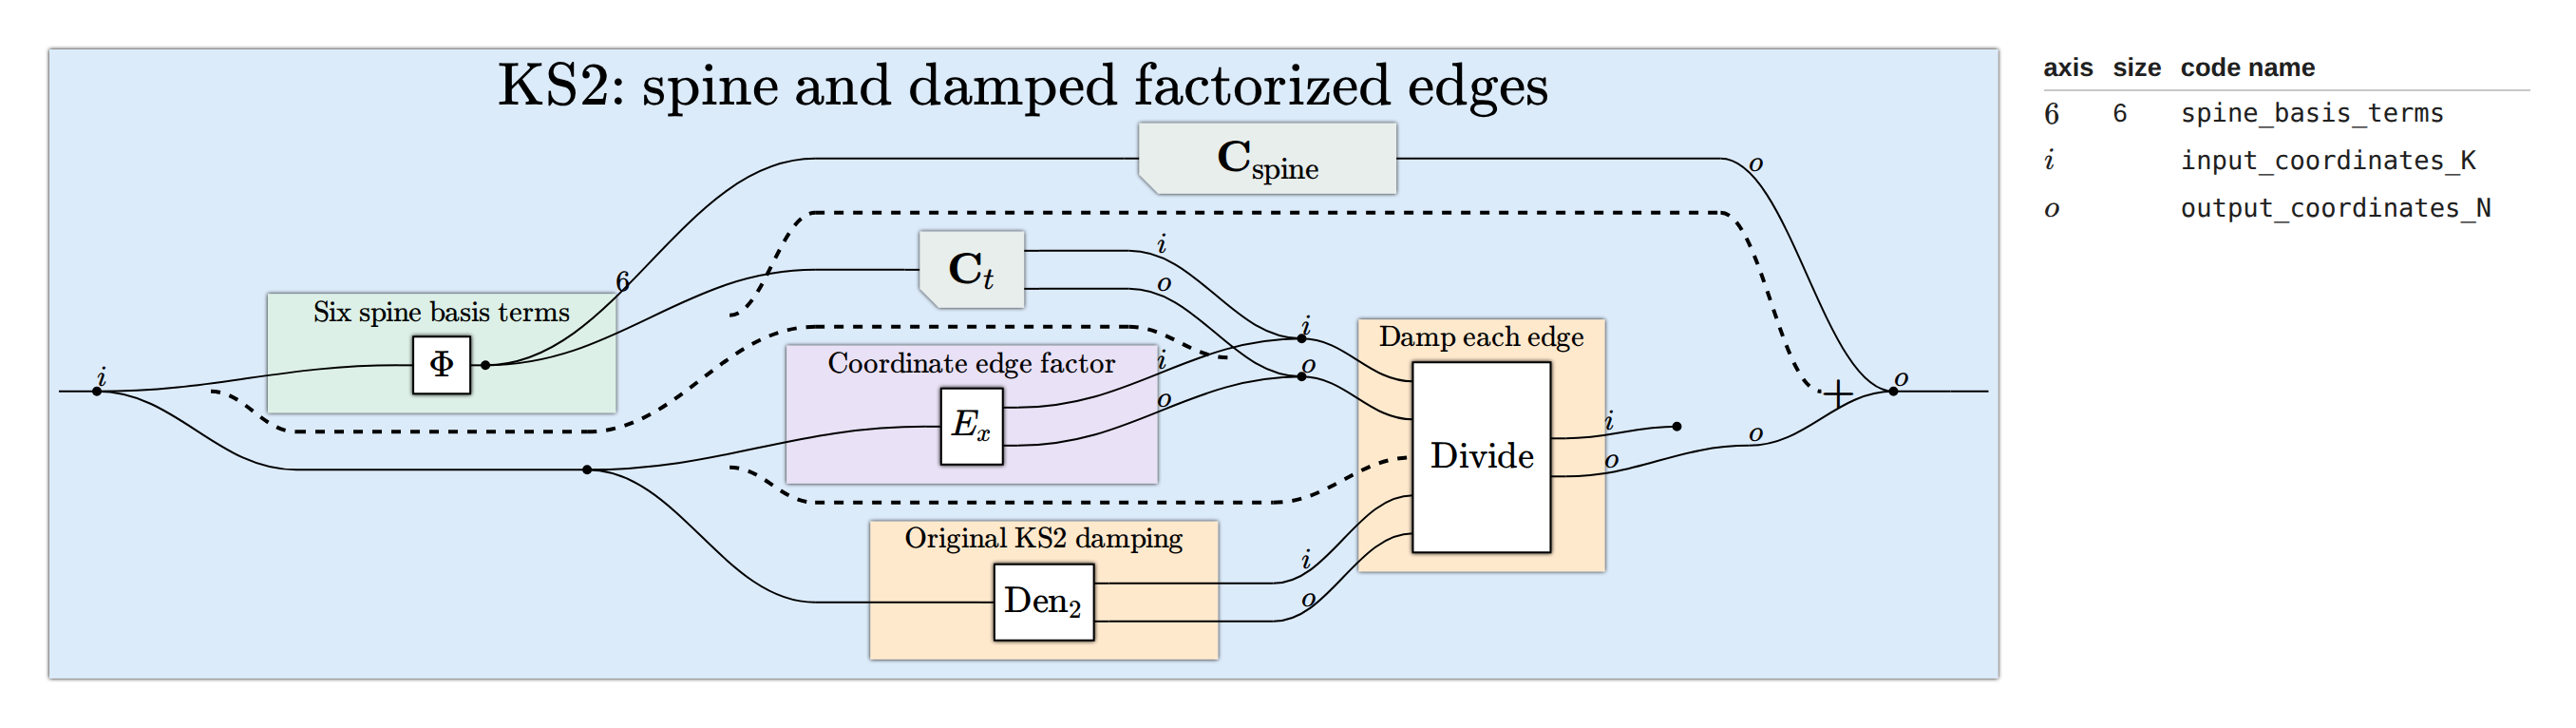

In [4]:
await show_figure("ks2-map")

### KS2Cell — projections and repeated geometry

Source: [`KS2Cell`](../../experiments/common/ks2.py). The direct map above
has no projections or loop. The cell adds them:
$$c^{(0)}=\operatorname{reshape}(W_{\rm down}x),\quad
c^{(j+1)}=c^{(j)}+G_2(c^{(j)}),\quad
y=W_{\rm up}\operatorname{vec}(c^{(L)}).$$
The diagram uses the default **two steps**, with the **same parameters** in
both steps. Charts own separate parameters. Defaults are $S=4$, $R=8$;
all these sizes and `geo_steps` are configurable. There is no ReLU or outer
input residual in this cell.

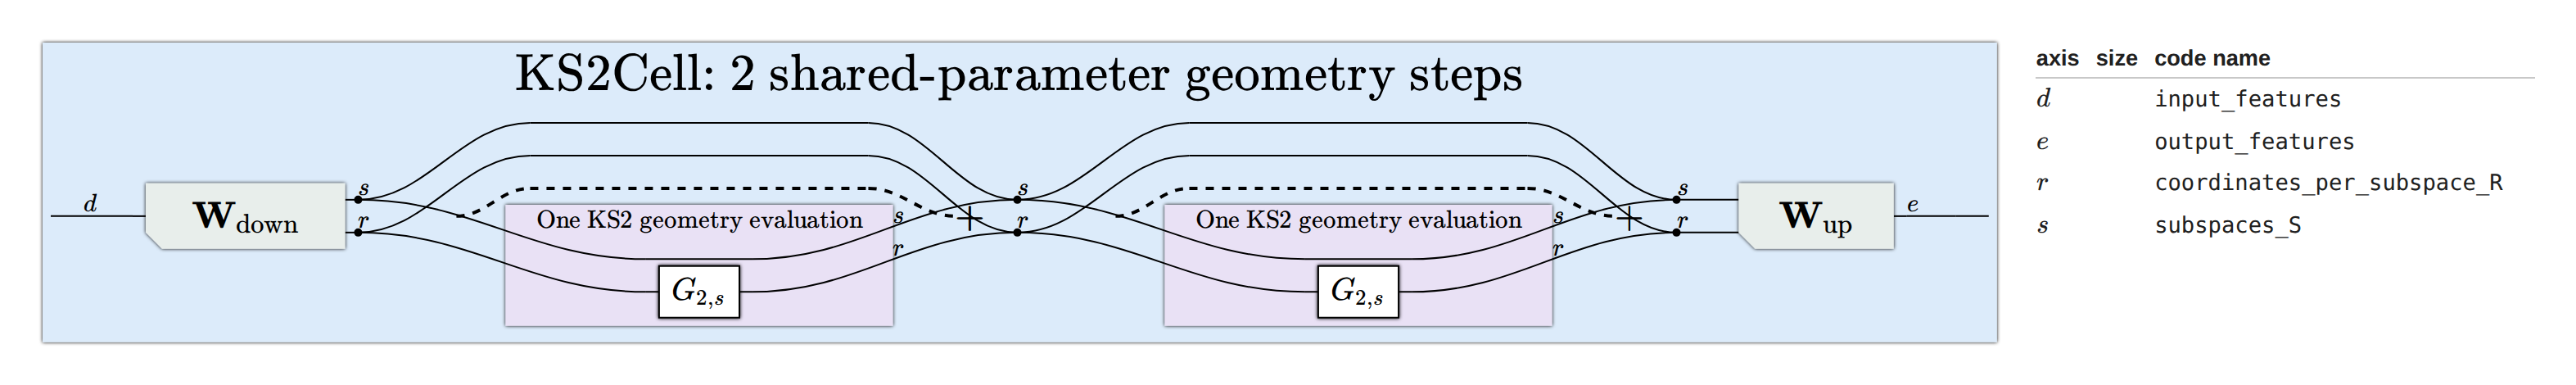

In [5]:
await show_figure("ks2-block")

**Stabilized KS2 is a separate implementation.**
[`ks2_stabilized.py`](../../experiments/common/ks2_stabilized.py) preserves
the spine/edge structure and parameter layout, but clamps coordinates,
computes geometry in FP32, uses $t=4\tanh(\operatorname{mean}(x)/4)$,
and replaces the denominator predicates with normalized squared deviation
and coordinate energy. Its damping strengths use a bounded scaled sigmoid;
`KS2StabilizedCell` defaults to one step. The original KS2 diagrams above
should not be read as the stabilized numerical formulas.

## KS3 — bounded spine, coordinate bypass, ReLU²

Source: [`KS3`](../../experiments/common/ks3.py). After the bias-free down
projection and reshape, coordinates are promoted for geometry and clamped
to $[-65504,65504]$. In each chart:
$$t_s=4\tanh(\operatorname{mean}_r(c_{sr})/4),\quad
z_s=z(t_s;a_s,b_s),$$
$$H_{sr}=h_{00}(t_s)p_{0,sr}+h_{01}(t_s)p_{1,sr}
+h_{10}(t_s)p_{2,sr}+h_{11}(t_s)p_{3,sr},$$
$$C_{sr}=p_{4,sr}T_2(z_s)+p_{5,sr}T_3(z_s),\quad
y=W_{\rm up}\operatorname{vec}\left[\operatorname{ReLU}(c+H+C)^2\right].$$
The code evaluates both polynomials in Horner form. There are six coefficients
per chart/output coordinate, plus one raw scale and shift per chart. For
rank $R>1$, output coordinates share the chart mean and warp, but have
separate coefficients and retain their own coordinate bypasses.

KS3 has **no edge terms, edge damping, or geometry loop**. Its bounded mean
lies in $(-4,4)$, not $[0,1]$. Normalization, attention, time mixing and the
outer residual belong to the enclosing model. The figure describes the
floating-point reference; [`KS3Int8`](../../experiments/common/ks3_int8.py)
adds quantized projections and a distinct precision/training path.

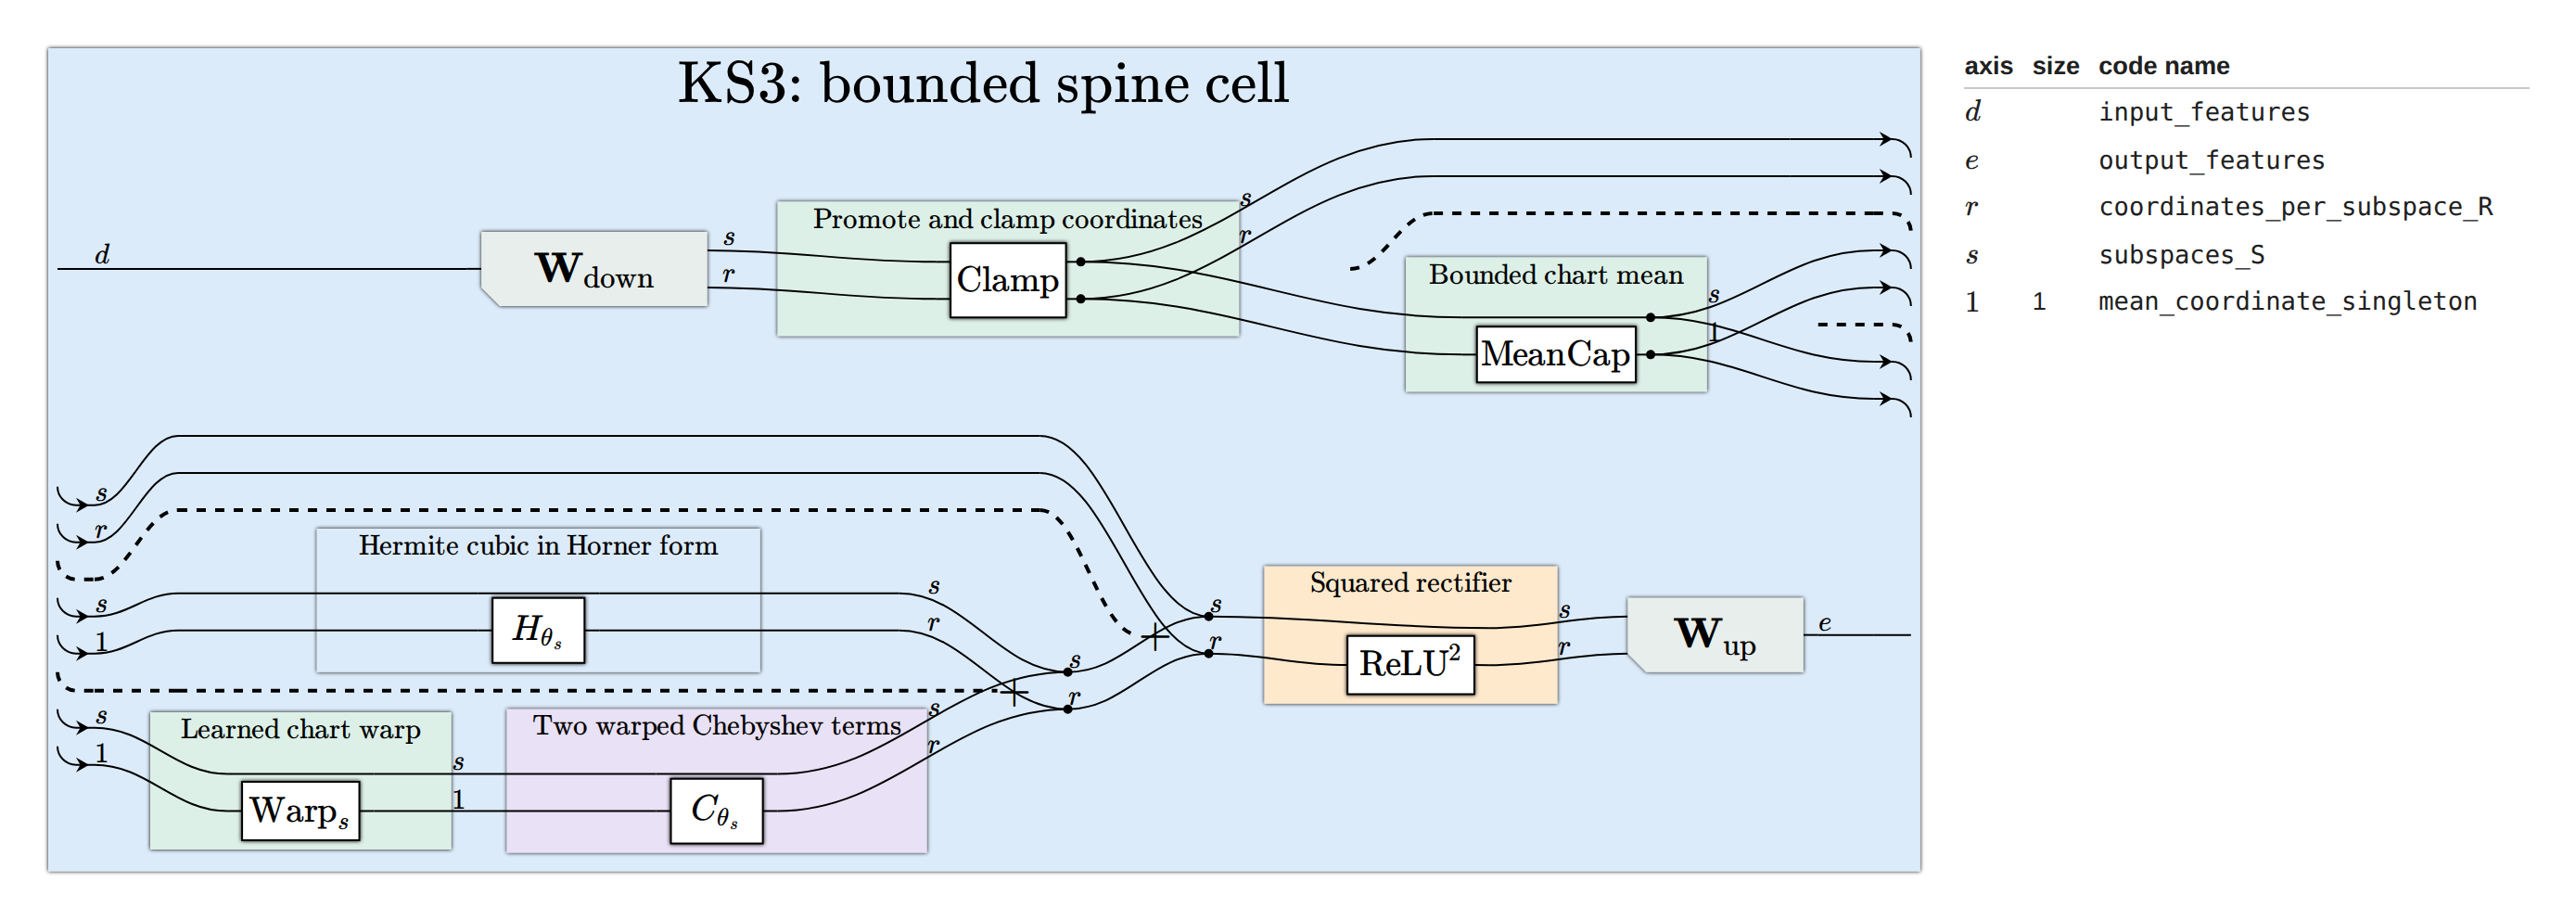

In [6]:
await show_figure("ks3-block")

## Compare the boundaries

Here $D_{\rm in/out}$ are feature widths; $K,N$ are direct-map dimensions;
$S,R$ are chart count and rank. Control counts assume all displayed geometric
controls are learned. Projection biases are absent.

| Construction | Geometric controls / total parameters | Internal bypass | Activation |
|---|---|---|---|
| KS1 direct map | $2N+6KN$ controls; $\sigma,\epsilon$ supplied separately | None | None |
| KS1Denoiser | $S[R(D_{\rm in}+D_{\rm out})+2R+6R^2]$, with widths 169 and $R=8$ | Once, in chart space | Tanh on map input only |
| KS2 direct map | $6N+12KN+4$ | None | Tanh warps only |
| KS2Cell | $S[R(D_{\rm in}+D_{\rm out})+6R+12R^2+4]$ | Every shared geometry step | Tanh warps only |
| KS3 | $S[R(D_{\rm in}+D_{\rm out}+6)+2]$ | Once, before ReLU² | Bounded mean, tanh warp, ReLU² |

Increasing KS2 `geo_steps` reuses weights and does not increase parameter
count. The README's $D_{\rm in}=D_{\rm out}=96$, $S=368$, $R=1$ KS3 example
has **73,600** parameters. Equal feature widths do not imply equal capacity.

In [7]:
# Arithmetic check for the documented KS3 configuration; no model allocation.
d_in, d_out, charts, rank = 96, 96, 368, 1
parameters = charts * (rank * (d_in + d_out + 6) + 2)
assert parameters == 73_600
print(f"KS3 (96 -> 96, 368 charts, rank 1): {parameters:,} parameters")

KS3 (96 -> 96, 368 charts, rank 1): 73,600 parameters


## Regenerate or edit the diagrams

The default display path only needs `ipython` and the local PNGs. To edit
the diagrams, use Python **3.13+** and Node/npm in an isolated tooling
environment. The pinned revisions below match the RHAC reference:

```bash
mkdir -p /tmp/ks-diagram-tools
cd /tmp/ks-diagram-tools
git clone https://github.com/mit-zardini-lab/pyncd.git
git -C pyncd checkout a051f8f2df12be97bb438a7b19980513fbe11c36
git clone https://github.com/mit-zardini-lab/tsncd.git
git -C tsncd checkout 70034600050b8297a3fe91ca7b6cc75c1d26bbc2
(cd tsncd && npm ci && npm run build)
python3.13 -m venv venv
venv/bin/python -m pip install websockets playwright ipython pandas pillow nbformat nbclient ipykernel
venv/bin/python -m playwright install chromium
export PYTHONPATH=/tmp/ks-diagram-tools/pyncd
export TSNCD_DIST=/tmp/ks-diagram-tools/tsncd/dist

# Substitute the path to this checkout. --check validates axis signatures only.
venv/bin/python /path/to/k-splanifolds/scripts/draw_ks_blocks.py --check
venv/bin/python /path/to/k-splanifolds/scripts/draw_ks_blocks.py
```

The generator validates all five input/output signatures, renders PNGs,
writes readable operation listings and JSON diagrams, builds the interactive
companion, and executes this notebook with saved outputs. Alternatively,
start a notebook kernel in this environment with the two environment
variables above and set `RENDER = True`. Edit the named diagram factories
in `scripts/draw_ks_blocks.py`, then restart the kernel before rebuilding.

[`provenance.json`](provenance.json) records tool revisions, source hashes
and the inspected project revision. Graph signatures and notebook execution
validate the documentation artifacts; they are not model quality tests.